# Notebook 05 — Baseline Model and Class-Imbalance Strategies

**Goal:** train and compare practical baseline models using the chronological split from Notebook 04.


In [1]:
from pathlib import Path
import json
import time
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline
from sklearn.dummy import DummyClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (
    average_precision_score, precision_score, recall_score, f1_score,
    roc_auc_score, confusion_matrix, classification_report
)

warnings.filterwarnings("ignore", category=FutureWarning)

PROJECT_ROOT = Path.cwd()
if not (PROJECT_ROOT / "data" / "processed").exists() and (PROJECT_ROOT.parent / "data" / "processed").exists():
    PROJECT_ROOT = PROJECT_ROOT.parent

DATA_PATH = PROJECT_ROOT / "data" / "processed" / "transactions_features.csv.gz"
SPLIT_CONFIG_PATH = PROJECT_ROOT / "notebooks" / "outputs" / "split_config.json"
OUTPUT_DIR = PROJECT_ROOT / "notebooks" / "outputs"
MODEL_DIR = PROJECT_ROOT / "models"
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
MODEL_DIR.mkdir(parents=True, exist_ok=True)

print("Project root:", PROJECT_ROOT)
print("Feature data exists:", DATA_PATH.exists())
print("Split config exists:", SPLIT_CONFIG_PATH.exists())

if not DATA_PATH.exists():
    raise FileNotFoundError("Run Notebook 03 first: transactions_features.csv.gz was not found.")
if not SPLIT_CONFIG_PATH.exists():
    raise FileNotFoundError("Run Notebook 04 first: split_config.json was not found.")

Project root: c:\Users\Tanish.Ranjan\OneDrive - ENCORA\Desktop\fraud-detection-system
Feature data exists: True
Split config exists: True


In [2]:
with open(SPLIT_CONFIG_PATH, "r", encoding="utf-8") as f:
    split_config = json.load(f)

TARGET = split_config["target_column"]
TIME_COL = split_config["time_column"]
CUTOFF_STEP = int(split_config["cutoff_step"])

# Load only columns needed for this experiment to reduce memory use.
df = pd.read_csv(DATA_PATH, compression="gzip")
print("Loaded shape:", df.shape)
print("Target:", TARGET, "| Time column:", TIME_COL, "| Cutoff step:", CUTOFF_STEP)

if TARGET not in df.columns or TIME_COL not in df.columns:
    raise ValueError("Target or time column is missing from the feature dataset.")

train_df = df.loc[df[TIME_COL] <= CUTOFF_STEP].copy()
test_df = df.loc[df[TIME_COL] > CUTOFF_STEP].copy()

print(f"Train rows: {len(train_df):,}; fraud: {int(train_df[TARGET].sum()):,}")
print(f"Test rows: {len(test_df):,}; fraud: {int(test_df[TARGET].sum()):,}")

if train_df.empty or test_df.empty:
    raise ValueError("Train or test partition is empty.")
if train_df[TIME_COL].max() >= test_df[TIME_COL].min():
    raise ValueError("Time leakage check failed: train steps overlap the test period.")

Loaded shape: (6362620, 22)
Target: isFraud | Time column: step | Cutoff step: 594
Train rows: 6,239,040; fraud: 6,559
Test rows: 123,580; fraud: 1,654


## Choose the initial predictors


In [3]:
excluded_columns = {
    TARGET, "isFlaggedFraud", "nameOrig", "nameDest", TIME_COL
}
feature_columns = [c for c in df.columns if c not in excluded_columns]

if "type" not in feature_columns:
    raise ValueError("Expected categorical feature 'type' was not found.")

# Keep all fraud training rows and sample normal training rows.
# Adjust NORMALS_PER_FRAUD for speed/RAM: 20 is a starting point, not a universal optimum.
NORMALS_PER_FRAUD = 20
RANDOM_STATE = 42

train_fraud = train_df.loc[train_df[TARGET] == 1]
train_normal = train_df.loc[train_df[TARGET] == 0]

normal_sample_size = min(len(train_normal), max(1, len(train_fraud) * NORMALS_PER_FRAUD))
train_normal_sample = train_normal.sample(n=normal_sample_size, random_state=RANDOM_STATE)

train_sample = pd.concat([train_fraud, train_normal_sample], axis=0)
train_sample = train_sample.sample(frac=1, random_state=RANDOM_STATE).reset_index(drop=True)

print("Number of predictors:", len(feature_columns))
print("Predictors:", feature_columns)
print(f"Sampled training rows: {len(train_sample):,}")
print(f"Fraud rows in sample: {int(train_sample[TARGET].sum()):,}")
print(f"Normal rows in sample: {int((train_sample[TARGET] == 0).sum()):,}")
print(f"Sampling ratio: up to {NORMALS_PER_FRAUD} normal rows per fraud row")

Number of predictors: 17
Predictors: ['type', 'amount', 'oldbalanceOrg', 'newbalanceOrig', 'oldbalanceDest', 'newbalanceDest', 'hour_of_day', 'origin_emptied', 'destination_balance_zero', 'origin_balance_error', 'destination_balance_error', 'origin_balance_error_abs', 'destination_balance_error_abs', 'night_flag', 'amount_to_origin_balance_ratio', 'origin_balance_was_zero', 'origin_txn_count_prior_steps']
Sampled training rows: 137,739
Fraud rows in sample: 6,559
Normal rows in sample: 131,180
Sampling ratio: up to 20 normal rows per fraud row


In [4]:
# Separate X and y. Ensure categorical and numeric types are handled explicitly.
X_train = train_sample[feature_columns].copy()
y_train = train_sample[TARGET].astype("int8").copy()

X_test = test_df[feature_columns].copy()
y_test = test_df[TARGET].astype("int8").copy()

categorical_features = X_train.select_dtypes(include=["object", "category"]).columns.tolist()
numeric_features = [c for c in feature_columns if c not in categorical_features]

# Booleans can be used as numeric 0/1 features.
for col in numeric_features:
    X_train[col] = pd.to_numeric(X_train[col], errors="coerce")
    X_test[col] = pd.to_numeric(X_test[col], errors="coerce")

numeric_transformer = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])
categorical_transformer = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("onehot", OneHotEncoder(handle_unknown="ignore"))
])

preprocessor = ColumnTransformer(transformers=[
    ("num", numeric_transformer, numeric_features),
    ("cat", categorical_transformer, categorical_features)
], remainder="drop")

print("Numeric features:", numeric_features)
print("Categorical features:", categorical_features)
print("Preprocessing will be fitted on training data only.")

Numeric features: ['amount', 'oldbalanceOrg', 'newbalanceOrig', 'oldbalanceDest', 'newbalanceDest', 'hour_of_day', 'origin_emptied', 'destination_balance_zero', 'origin_balance_error', 'destination_balance_error', 'origin_balance_error_abs', 'destination_balance_error_abs', 'night_flag', 'amount_to_origin_balance_ratio', 'origin_balance_was_zero', 'origin_txn_count_prior_steps']
Categorical features: ['type']
Preprocessing will be fitted on training data only.


C:\Users\Tanish.Ranjan\AppData\Local\Temp\ipykernel_2228\3099464673.py:8: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  categorical_features = X_train.select_dtypes(include=["object", "category"]).columns.tolist()


## Train and evaluate models



In [5]:
models = {
    "Dummy (most frequent)": DummyClassifier(strategy="most_frequent"),
    "Logistic Regression (balanced)": LogisticRegression(
        class_weight="balanced",
        max_iter=300,
        solver="liblinear",
        random_state=RANDOM_STATE
    ),
    "Random Forest (balanced)": RandomForestClassifier(
        n_estimators=120,
        max_depth=16,
        min_samples_leaf=3,
        class_weight="balanced_subsample",
        n_jobs=-1,
        random_state=RANDOM_STATE
    )
}

results = []
fitted_models = {}
predictions = {}

for model_name, estimator in models.items():
    print("\n" + "=" * 75)
    print("Training:", model_name)
    model = Pipeline(steps=[
        ("preprocessor", preprocessor),
        ("classifier", estimator)
    ])
    start = time.time()
    model.fit(X_train, y_train)
    fit_seconds = time.time() - start

    start = time.time()
    y_pred = model.predict(X_test)
    predict_seconds = time.time() - start

    # DummyClassifier may not expose meaningful probabilities for both classes in every setup.
    if hasattr(model, "predict_proba"):
        y_score = model.predict_proba(X_test)[:, 1]
    else:
        y_score = y_pred.astype(float)

    ap = average_precision_score(y_test, y_score)
    roc = roc_auc_score(y_test, y_score) if len(np.unique(y_test)) == 2 else np.nan
    precision = precision_score(y_test, y_pred, zero_division=0)
    recall = recall_score(y_test, y_pred, zero_division=0)
    f1 = f1_score(y_test, y_pred, zero_division=0)
    cm = confusion_matrix(y_test, y_pred, labels=[0, 1])

    results.append({
        "model": model_name,
        "average_precision": ap,
        "roc_auc": roc,
        "precision_at_0.50": precision,
        "recall_at_0.50": recall,
        "f1_at_0.50": f1,
        "fit_seconds": fit_seconds,
        "predict_seconds": predict_seconds,
        "true_negative": int(cm[0, 0]),
        "false_positive": int(cm[0, 1]),
        "false_negative": int(cm[1, 0]),
        "true_positive": int(cm[1, 1])
    })
    fitted_models[model_name] = model
    predictions[model_name] = (y_pred, y_score)

    print(f"Fit seconds: {fit_seconds:.1f} | Prediction seconds: {predict_seconds:.1f}")
    print(f"Average Precision: {ap:.6f}")
    print(f"ROC-AUC: {roc:.6f}")
    print(f"Precision: {precision:.4f} | Recall: {recall:.4f} | F1: {f1:.4f}")
    print("Confusion matrix [[TN, FP], [FN, TP]]:")
    print(cm)

results_df = pd.DataFrame(results).sort_values("average_precision", ascending=False)
display(results_df)


Training: Dummy (most frequent)
Fit seconds: 0.6 | Prediction seconds: 0.1
Average Precision: 0.013384
ROC-AUC: 0.500000
Precision: 0.0000 | Recall: 0.0000 | F1: 0.0000
Confusion matrix [[TN, FP], [FN, TP]]:
[[121926      0]
 [  1654      0]]

Training: Logistic Regression (balanced)
Fit seconds: 3.8 | Prediction seconds: 0.2
Average Precision: 0.959298
ROC-AUC: 0.998455
Precision: 0.3687 | Recall: 0.9915 | F1: 0.5375
Confusion matrix [[TN, FP], [FN, TP]]:
[[119118   2808]
 [    14   1640]]

Training: Random Forest (balanced)
Fit seconds: 8.9 | Prediction seconds: 0.5
Average Precision: 0.999999
ROC-AUC: 1.000000
Precision: 0.9988 | Recall: 0.9994 | F1: 0.9991
Confusion matrix [[TN, FP], [FN, TP]]:
[[121924      2]
 [     1   1653]]


,model,average_precision,roc_auc,precision_at_0.50,recall_at_0.50,f1_at_0.50,fit_seconds,predict_seconds,true_negative,false_positive,false_negative,true_positive
2,Random Forest (balanced),0.999999,1.000000,0.998792,0.999395,0.999093,8.910905,0.464449,121924,2,1,1653
1,Logistic Regression (balanced),0.959298,0.998455,0.368705,0.991536,0.537529,3.794824,0.164256,119118,2808,14,1640
0,Dummy (most frequent),0.013384,0.500000,0.000000,0.000000,0.000000,0.555375,0.093889,121926,0,1654,0


Best model by Average Precision: Random Forest (balanced)
Saved model comparison: c:\Users\Tanish.Ranjan\OneDrive - ENCORA\Desktop\fraud-detection-system\notebooks\outputs\baseline_model_comparison.csv


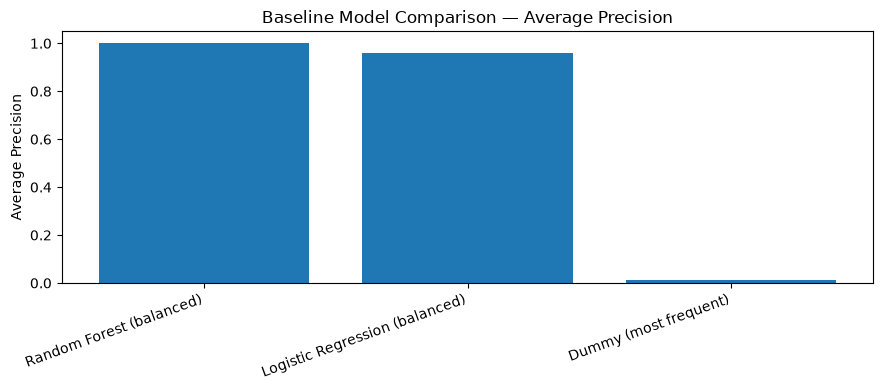

In [6]:
# Save the comparison report and show the best model by Average Precision.
RESULTS_PATH = OUTPUT_DIR / "baseline_model_comparison.csv"
results_df.to_csv(RESULTS_PATH, index=False)

best_model_name = results_df.iloc[0]["model"]
print("Best model by Average Precision:", best_model_name)
print("Saved model comparison:", RESULTS_PATH)

# Plot Average Precision (AP).
plt.figure(figsize=(9, 4))
plt.bar(results_df["model"], results_df["average_precision"])
plt.xticks(rotation=20, ha="right")
plt.ylabel("Average Precision")
plt.title("Baseline Model Comparison — Average Precision")
plt.tight_layout()
plt.show()

## Interpretation and limitations



In [7]:
print("NOTEBOOK 05 — BASELINE MODEL SUMMARY")
print("-" * 48)
print(f"Training sample rows: {len(X_train):,}")
print(f"Full chronological test rows: {len(X_test):,}")
print("Models compared:", ", ".join(results_df["model"].tolist()))
print("Best model by Average Precision:", best_model_name)
print("Comparison report exists:", RESULTS_PATH.exists())
print("Remember: model scores are initial baselines; threshold tuning and leakage review are still required.")

NOTEBOOK 05 — BASELINE MODEL SUMMARY
------------------------------------------------
Training sample rows: 137,739
Full chronological test rows: 123,580
Models compared: Random Forest (balanced), Logistic Regression (balanced), Dummy (most frequent)
Best model by Average Precision: Random Forest (balanced)
Comparison report exists: True
Remember: model scores are initial baselines; threshold tuning and leakage review are still required.
